In [1]:
# CPU/GPU selection: run this cell before importing jax or CSP_JAX elsewhere.
# After changing MODE, restart the kernel and run all cells from the top.
# GPU mode requires CUDA-enabled JAX in a Linux/WSL2 kernel.
import os

MODE = "cpu"  # "cpu" or "gpu"
if MODE not in {"cpu", "gpu"}:
    raise ValueError('MODE must be "cpu" or "gpu".')

# Keep CPU available in GPU mode for operations explicitly placed on CPU.
os.environ["JAX_PLATFORMS"] = "cpu" if MODE == "cpu" else "cuda,cpu"

import jax
backend = jax.default_backend()
if backend != MODE:
    raise RuntimeError("Device mode has changed: restart the kernel and run all cells.")
print("Backend:", backend)
print("Devices:", jax.devices())


Backend: cpu
Devices: [CpuDevice(id=0)]


# Demo 2: CSP factor model — sparse random loadings, heteroscedastic noise (`GibbsCSP`)

**Model**: $x_i = B\eta_i + \varepsilon_i$, $\eta_i \sim \mathcal N_H(0, I_H)$,
$\varepsilon_i \sim \mathcal N_p(0, \Omega)$ with $\Omega = \mathrm{diag}(\sigma_1^2, \dots, \sigma_p^2)$.
The loading columns carry the cumulative-shrinkage-process (CSP) spike-and-slab prior.

**Data design** (same design as the CSP demo2 experiment, $n = 100 \ll p = 1000$, $r = 5$ true factors):

- entries of $B_0$ are $\mathrm{Bernoulli}(1/3) \times U(0.5, 1.5)$ — sparse random loadings with about 2/3 exact zeros;
- $\Omega_0 = \mathrm{diag}(\sigma_j^2)$ with $\sigma_j^2 \sim U(0.1, 1.0)$ — **heteroscedastic** noise (unlike Demo 1);
- $\Sigma_0 = B_0 B_0^\top + \Omega_0$.

Why $U(0.5, 1.5)$ rather than $U(0, 1)$: under the CSP prior a spiked column is not driven to zero — it retains $N(0, \theta_\infty)$ prior noise, i.e. energy $\sim \sqrt{p\,\theta_\infty} \approx 7.1$ at $p = 1000$ and $\theta_\infty = 0.05$. Signal columns must clear that floor for the dimension to be identifiable.

**Inference**: `GibbsCSP` (exact MCMC). All noise, covariance, subspace, uncertainty, and mixing diagnostics below use the **raw** draws and are computed **before** RSP; the single `align_factors()` call is in Section 8.


In [2]:
import hashlib
import sys
import time
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

# The notebook lives in CSP_BFM/demos/: walk up to the directory containing
# the CSP_JAX package and put it on sys.path.
root = next(d for d in (Path.cwd(), *Path.cwd().parents) if (d / "CSP_JAX").is_dir())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import jax
from CSP_JAX import GibbsCSP

# ---------------------------------------------------------------------------
# Consistent, publication-friendly plotting style.
# ---------------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#5b6472",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6eaf0",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlepad": 8,
    "axes.labelsize": 10,
    "axes.labelcolor": "#30363f",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "xtick.color": "#30363f",
    "ytick.color": "#30363f",
    "legend.fontsize": 9,
    "legend.frameon": False,
    "font.family": "DejaVu Sans",
})
C_GS, C_TRUE, C_SHRUNK = "#2f6fd0", "#b03a2e", "#c9d3df"

print("package root:", root, "| jax backend:", jax.default_backend())


package root: C:\Users\kexio\Documents\GitHub\CSP_BFM | jax backend: cpu


In [3]:
# Experiment configuration: explicit seeds, CSP prior, and MCMC schedule.
DATA_SEED = 2          # data-generating seed (same design as the CSP demo2 experiment)
SAMPLER_SEED = 2025    # one explicit PRNGKey for Gibbs and factor scores

P, K0, N = 1000, 5, 100  # variables, true factors, observations

H = 50                  # CSP truncation; at most H - 1 columns can be active
ALPHA = 5.0             # prior expected number of active factors
A_THETA, B_THETA = 2.0, 2.0
THETA_INF = 0.05        # spike variance (not a standard deviation)
A_SIGMA, B_SIGMA = 1.0, 0.3
N_ITER, BURN_IN, THIN = 20000, 10000, 10

SPIKE_FLOOR = float(np.sqrt(P * THETA_INF))  # ~ sqrt(p * theta_inf)

print(f"seeds: data={DATA_SEED}, sampler={SAMPLER_SEED}")
print(f"p={P}, n={N}, true r={K0}; H={H}, alpha={ALPHA:g}, "
      f"theta_inf={THETA_INF:g}, spike floor~{SPIKE_FLOOR:.2f}")
print(f"MCMC: {N_ITER} sweeps, burn-in {BURN_IN}, thin {THIN} -> "
      f"{(N_ITER - BURN_IN) // THIN} kept draws")


seeds: data=2, sampler=2025
p=1000, n=100, true r=5; H=50, alpha=5, theta_inf=0.05, spike floor~7.07
MCMC: 20000 sweeps, burn-in 10000, thin 10 -> 1000 kept draws


## 1. Simulate the data (same design and seed)

The estimator centers the columns internally (`center=True` by default), so `X` is passed uncentered — unlike the raw `GS_CSP` driver, which assumes a zero-mean input. `DATA_SEED = 2` reproduces the sparse random-loading design with nonzero entries in $U(0.5, 1.5)$.


In [4]:
np.random.seed(DATA_SEED)

B_0 = np.random.binomial(1, 1 / 3, (P, K0)) * (0.5 + np.random.rand(P, K0))
s2_true = 0.1 + 0.9 * np.random.rand(P)        # in [0.1, 1.0]
cov_0 = B_0 @ B_0.T + np.diag(s2_true)
X = np.random.multivariate_normal(np.zeros(P), cov_0, N)
Sig_true = cov_0

assert X.shape == (N, P) and np.isfinite(X).all()
print(f"X: {X.shape}  (n = {N}, p = {P}, true factors r = {K0})")
print(f"loading sparsity (exact zeros): {(B_0 == 0).mean():.2%}")
print(f"true column norms: {np.round(np.linalg.norm(B_0, axis=0), 1).tolist()}"
      f"  (spike floor ~ {SPIKE_FLOOR:.1f})")


X: (100, 1000)  (n = 100, p = 1000, true factors r = 5)
loading sparsity (exact zeros): 68.00%
true column norms: [18.5, 18.7, 18.6, 19.0, 18.8]  (spike floor ~ 7.1)


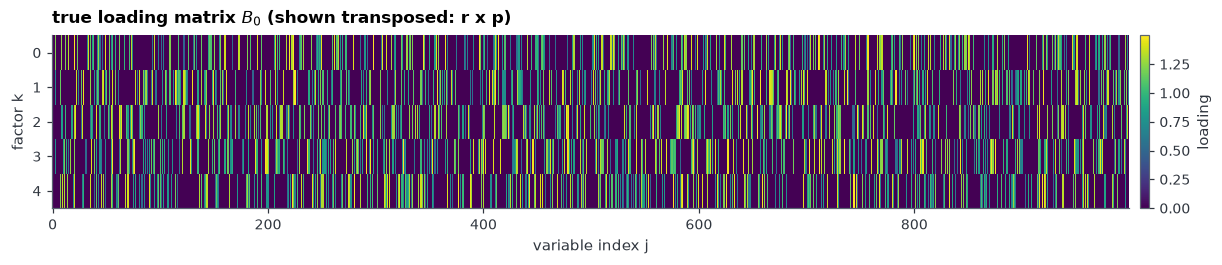

In [5]:
fig, ax = plt.subplots(figsize=(11, 2.3), constrained_layout=True)
im = ax.imshow(B_0.T, aspect="auto", interpolation="nearest", cmap="viridis")
ax.set_title("true loading matrix $B_0$ (shown transposed: r x p)", loc="left")
ax.set_xlabel("variable index j")
ax.set_ylabel("factor k")
ax.set_yticks(np.arange(K0))
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("loading")
plt.show()


## 2. Fit the CSP Gibbs sampler

* Truncation level **H = 50**, generously larger than the true r = 5: at most H − 1 columns can be active (the Hth is spiked by construction, since $v_H = 1$), and the increasing spike mass $\pi_h$ should absorb the redundant ones. The paper's conservative choice is H = p + 1, far larger than practical at p = 1000; Section 3.3 notes that far fewer columns typically suffice. The prior expected active count is $E(H^*) = \alpha = 5$ before truncation.
* Hyperparameters follow Section 4 of the paper: `alpha = 5`, `a_theta = b_theta = 2`, `theta_inf = 0.05`, `(a_sigma, b_sigma) = (1, 0.3)`; `a_theta > 1` satisfies the condition of Theorem 2.
* 20000 sweeps, 10000 burn-in, keep every 10th → S = 1000 kept draws (thinning reduces autocorrelation and host memory at H = 50).
* `seed` seeds one explicit `jax.random.PRNGKey` (no global RNG state); the used seed is stored as `seed_`.
* The first call includes one-time XLA ahead-of-time compilation (seconds, NOT counted in `runtime_sec_`).


In [6]:
t0 = time.perf_counter()
gs = GibbsCSP(H=H, alpha=ALPHA, a_theta=A_THETA, b_theta=B_THETA,
              theta_inf=THETA_INF, a_sigma=A_SIGMA, b_sigma=B_SIGMA,
              n_iter=N_ITER, burn_in=BURN_IN, thin=THIN,
              seed=SAMPLER_SEED, verbose=False).fit(X)
wall = time.perf_counter() - t0
S = gs.B_samples_.shape[0]

assert S == (N_ITER - BURN_IN) // THIN
assert gs.seed_ == SAMPLER_SEED
print("-" * 78)
print(f"GibbsCSP | H={gs.H} | {S} kept draws (every {gs.thin}th of "
      f"{gs.n_iter - gs.burn_in} post-burn-in sweeps) | "
      f"scan {gs.runtime_sec_:.1f}s "
      f"({1e3 * gs.runtime_sec_ / gs.n_iter:.1f} ms/sweep) | wall {wall:.1f}s "
      f"(includes one-time XLA compilation)")
print("-" * 78)


------------------------------------------------------------------------------
GibbsCSP | H=50 | 1000 kept draws (every 10th of 10000 post-burn-in sweeps) | scan 302.2s (15.1 ms/sweep) | wall 309.8s (includes one-time XLA compilation)
------------------------------------------------------------------------------


## 3. Automatic selection of the factor dimension via $H^*$

The CSP prior's headline feature: the number of active factors $H^* = \sum_h \mathbb 1(z_h > h)$ is sampled every sweep, so its posterior estimates the model dimension directly. `n_factors()` defaults to the posterior median of $H^*$; `method="credible"` is a secondary entry-wise marginal credible-interval rule. The shrinking column norms show the same picture: columns beyond the true dimension are absorbed by the spike at $\theta_\infty = 0.05$.

The third panel plots the mean over draws of each draw's column norm, $\frac{1}{S}\sum_s \|B^{(s)}_{\cdot h}\|_2$. Section 8a reports a different quantity, the $L_2$ (and $L_\infty$) norm of the **posterior-mean** column; the spike floor $\sqrt{p\,\theta_\infty}$ is a reference line, not a selection threshold.


H* posterior: mean = 5.00, median = 5, 95% CI = (5, 5)  (true r = 5, 1000 draws)
n_factors() [H* median, floored to int] = 5
n_factors('credible')   = 5


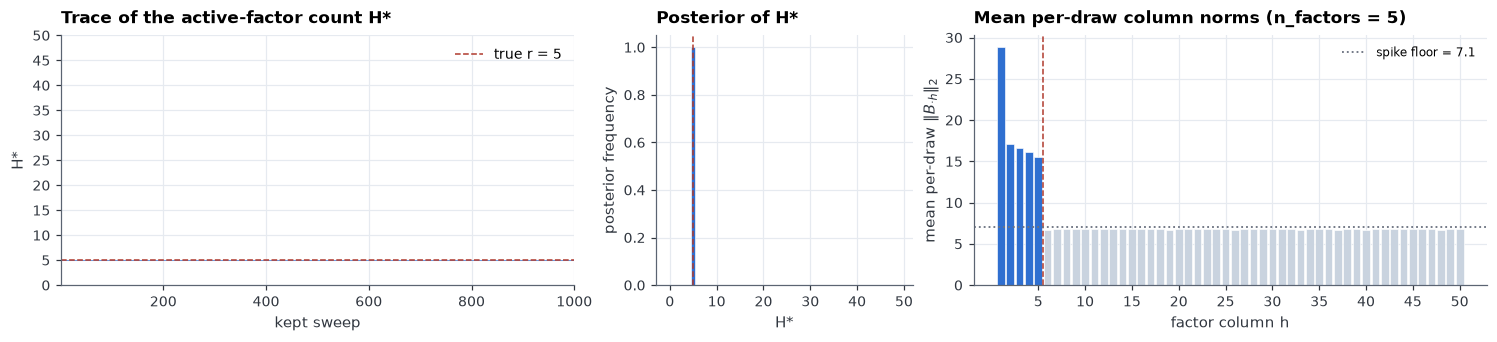

mean per-draw column L2 norms: [28.83  17.08  16.593 16.172 15.578  6.743  6.755  6.748  6.75   6.752
  6.756  6.748  6.752  6.752  6.756  6.75   6.748  6.758  6.74   6.754
  6.75   6.752  6.748  6.756  6.753  6.746  6.749  6.749  6.748  6.75
  6.756  6.752  6.746  6.75   6.748  6.749  6.742  6.748  6.747  6.738
  6.748  6.764  6.756  6.751  6.752  6.76   6.757  6.746  6.754  6.753]


In [7]:
summ = gs.h_star_summary()
r_h_star = gs.n_factors()
r_credible = gs.n_factors(method="credible")
print(f"H* posterior: mean = {summ['mean']:.2f}, median = {summ['median']:.0f}, "
      f"95% CI = ({summ['ci'][0]:.0f}, {summ['ci'][1]:.0f})  "
      f"(true r = {K0}, {summ['n_draws']} draws)")
print(f"n_factors() [H* median, floored to int] = {r_h_star}")
print(f"n_factors('credible')   = {r_credible}")

hs = gs.H_star_samples_
colnorm = np.linalg.norm(gs.B_samples_, axis=1).mean(0)
assert 0 <= int(hs.min()) and int(hs.max()) <= H - 1
assert 0 <= r_h_star <= H - 1

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.0), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.6, 0.8, 1.6]})
axes[0].plot(np.arange(1, S + 1), hs, color=C_GS, lw=0.6, alpha=0.7)
axes[0].axhline(K0, color=C_TRUE, ls="--", lw=1.0, label=f"true r = {K0}")
axes[0].set_xlabel("kept sweep")
axes[0].set_ylabel("H*")
axes[0].set_yticks(np.arange(0, H + 1, max(1, H // 10)))
axes[0].set_xlim(1, S)
axes[0].set_title("Trace of the active-factor count H*", loc="left")
axes[0].legend(loc="upper right")

counts = np.bincount(hs, minlength=H)
axes[1].bar(np.arange(H), counts / S, width=0.82, color=C_GS,
            edgecolor="white", linewidth=0.4)
axes[1].axvline(K0, color=C_TRUE, ls="--", lw=1.0)
axes[1].set_xlabel("H*")
axes[1].set_ylabel("posterior frequency")
axes[1].set_title("Posterior of H*", loc="left")

xs = np.arange(1, H + 1)
axes[2].bar(xs, colnorm, width=0.82,
            color=np.where(xs <= K0, C_GS, C_SHRUNK),
            edgecolor="white", linewidth=0.4)
axes[2].axvline(K0 + 0.5, color=C_TRUE, ls="--", lw=1.0)
axes[2].axhline(SPIKE_FLOOR, color="#6b7280", ls=":", lw=1.2,
                label=f"spike floor = {SPIKE_FLOOR:.1f}")
axes[2].set_xlabel("factor column h")
axes[2].set_ylabel(r"mean per-draw $\|B_{\cdot h}\|_2$")
axes[2].set_title(f"Mean per-draw column norms (n_factors = {r_h_star})", loc="left")
axes[2].set_xticks(np.arange(5, H + 1, 5))
axes[2].legend(loc="upper right", fontsize=8)
plt.show()

print("mean per-draw column L2 norms:", np.round(colnorm, 3))


## 4. Recovery of the heteroscedastic noise variances

Both panels use the raw posterior mean `sigma2_hat_`; `sigma2_hat_` is a mean of the raw noise draws and is unchanged by the RSP alignment in Section 8.


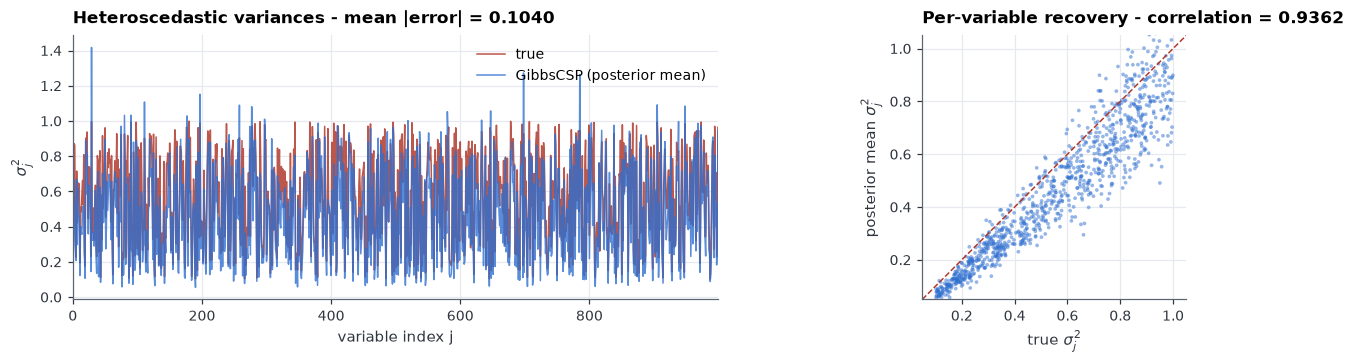

mean |error| = 0.1040; correlation with truth = 0.9362


In [8]:
err = float(np.abs(gs.sigma2_hat_ - s2_true).mean())
corr = float(np.corrcoef(s2_true, gs.sigma2_hat_)[0, 1])
assert gs.sigma2_hat_.shape == (P,)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.2), constrained_layout=True)
axes[0].plot(s2_true, color=C_TRUE, lw=1.0, alpha=0.85, label="true")
axes[0].plot(gs.sigma2_hat_, color=C_GS, lw=1.0, alpha=0.8,
             label="GibbsCSP (posterior mean)")
axes[0].set_xlabel("variable index j")
axes[0].set_ylabel(r"$\sigma_j^2$")
axes[0].set_title(f"Heteroscedastic variances - mean |error| = {err:.4f}",
                  loc="left")
axes[0].set_xlim(0, P - 1)
axes[0].legend(loc="upper right")

axes[1].scatter(s2_true, gs.sigma2_hat_, s=6, color=C_GS, alpha=0.5,
                edgecolors="none")
lim = (0.05, 1.05)
axes[1].plot(lim, lim, color=C_TRUE, ls="--", lw=1.0)
axes[1].set_xlabel(r"true $\sigma_j^2$")
axes[1].set_ylabel(r"posterior mean $\sigma_j^2$")
axes[1].set_title(f"Per-variable recovery - correlation = {corr:.4f}", loc="left")
axes[1].set_xlim(lim)
axes[1].set_ylim(lim)
axes[1].set_aspect("equal")
plt.show()

print(f"mean |error| = {err:.4f}; correlation with truth = {corr:.4f}")


## 5. Recovered loading structure (raw posterior mean, pre-RSP)

The loadings are shown **before** alignment: sign and column order are arbitrary across draws, so the raw mean can be attenuated where the chain switches. This section deliberately uses `B_samples_.mean(axis=0)`, not `B_hat_` after an alignment. The true matrix has $r = 5$ columns; the estimate has $H = 50$, and the trailing columns are shrunk toward the spike.


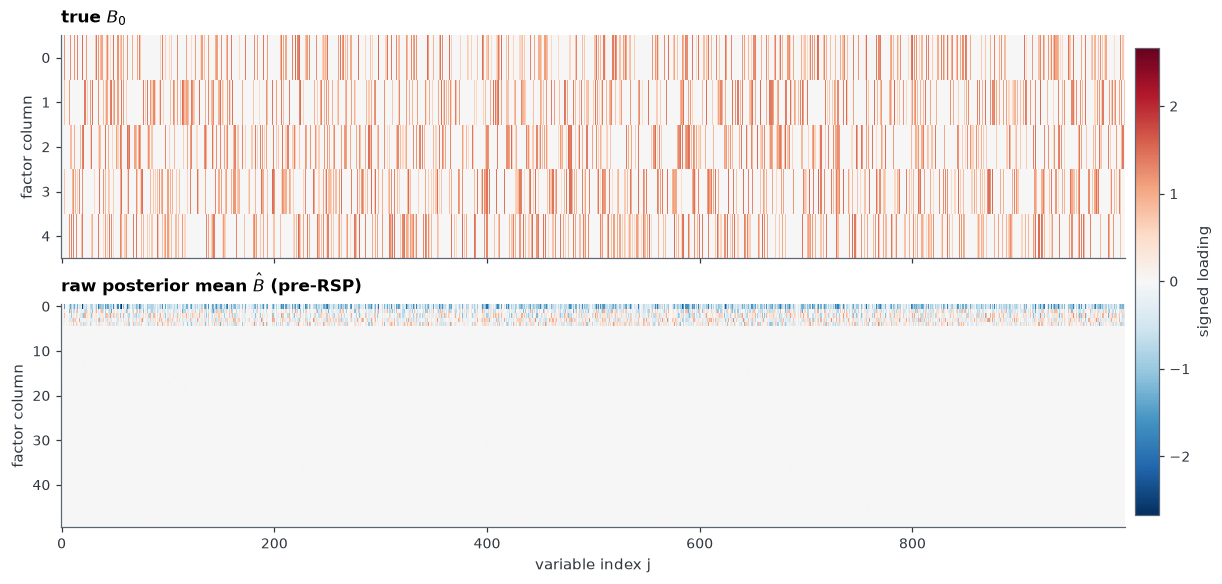

H* median (int) = 5; columns beyond it = 45 of 50 (at most H - 1 = 49 can be active; the last column is spiked by construction)
raw posterior-mean column L2 norms: [28.08 15.61 15.36 14.7  14.18  0.36  0.32  0.31  0.36  0.33  0.34  0.3
  0.32  0.38  0.3   0.38  0.39  0.3   0.34  0.36  0.36  0.33  0.35  0.34
  0.33  0.3   0.33  0.31  0.36  0.35  0.33  0.36  0.33  0.31  0.35  0.36
  0.36  0.42  0.3   0.35  0.34  0.32  0.36  0.29  0.33  0.32  0.43  0.32
  0.29  0.34]


In [9]:
B_raw_mean = gs.B_samples_.mean(axis=0)
assert B_raw_mean.shape == (P, H)
r_h_star = gs.n_factors()
assert 0 <= r_h_star <= H - 1
n_beyond = H - r_h_star

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), constrained_layout=True,
                         sharex=True)
limit = max(float(np.abs(B_0).max()), float(np.abs(B_raw_mean).max()))
for ax, (label, M) in zip(axes, (("true $B_0$", B_0),
                                 ("raw posterior mean $\\hat B$ (pre-RSP)",
                                  B_raw_mean))):
    im = ax.imshow(M.T, aspect="auto", interpolation="nearest",
                   cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(label, loc="left")
    ax.set_ylabel("factor column")
    ax.grid(False)
axes[1].set_xlabel("variable index j")
cb = fig.colorbar(im, ax=axes, pad=0.01, shrink=0.95)
cb.set_label("signed loading")
plt.show()

print(f"H* median (int) = {r_h_star}; columns beyond it = {n_beyond} of {H} "
      f"(at most H - 1 = {H - 1} can be active; the last column is spiked "
      "by construction)")
raw_l2 = np.linalg.norm(B_raw_mean, axis=0)
print("raw posterior-mean column L2 norms:", np.round(raw_l2, 2))


## 6a. Covariance and factor-subspace recovery (pre-RSP)

For each estimate report both the absolute and the relative Frobenius error,
\[
\text{Frobenius error}=\|\widehat\Sigma-\Sigma_0\|_F,
\qquad
\text{relative Frobenius error}
=\frac{\|\widehat\Sigma-\Sigma_0\|_F}{\|\Sigma_0\|_F}.
\]
The plug-in is built explicitly from the **raw** draws, `B_raw = B_samples_.mean(axis=0)` and `diag(sigma2_hat_)`; the Monte Carlo estimate is `Sigma_mc_`, the mean of the per-draw covariances. The raw plug-in does not change if Section 8 is rerun, and `Sigma_mc_` is invariant to per-draw orthogonal transforms by construction. Principal-angle cosines compare the span of the top-$r$ raw loading columns with the true factor space. The heatmaps that follow show the true covariance, the Monte Carlo mean, and the raw plug-in on one shared color scale.


Covariance estimation errors before RSP alignment
||Sigma_true||_F = 899.989857
Estimator / summary             Frobenius error   Relative Frobenius error
raw plug-in                          216.430490                   0.240481
Sigma_mc_ (MC mean)                  245.291006                   0.272549
principal-angle cosines (raw GibbsCSP): [0.9971 0.9908 0.9893 0.988  0.9865]


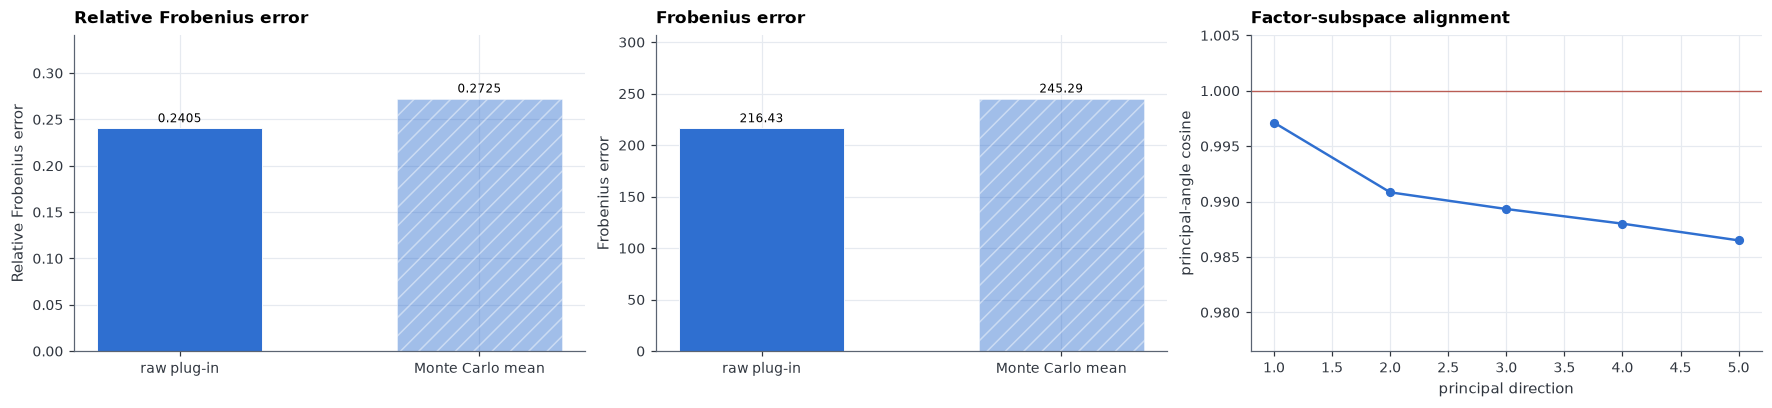

In [10]:
B_raw_mean = gs.B_samples_.mean(axis=0)
Sig_plug_raw = (B_raw_mean.astype(np.float64)
                @ B_raw_mean.astype(np.float64).T
                + np.diag(gs.sigma2_hat_.astype(np.float64)))
Sig_mc = gs.Sigma_mc_
assert Sig_plug_raw.shape == (P, P) and Sig_mc.shape == (P, P)

norm_Sig_true = float(np.linalg.norm(Sig_true, ord="fro"))


def froerr(Sig):
    return float(np.linalg.norm(Sig - Sig_true, ord="fro"))


def relerr(Sig):
    return froerr(Sig) / norm_Sig_true


fro_plug, fro_mc = froerr(Sig_plug_raw), froerr(Sig_mc)
rel_plug, rel_mc = relerr(Sig_plug_raw), relerr(Sig_mc)
print("Covariance estimation errors before RSP alignment")
print(f"||Sigma_true||_F = {norm_Sig_true:.6f}")
print(f"{'Estimator / summary':<26} {'Frobenius error':>20} "
      f"{'Relative Frobenius error':>26}")
for label, absolute, relative in (
    ("raw plug-in", fro_plug, rel_plug),
    ("Sigma_mc_ (MC mean)", fro_mc, rel_mc),
):
    print(f"{label:<26} {absolute:20.6f} {relative:26.6f}")

# Subspace alignment: principal-angle cosines between the span of the top-r
# raw loading columns and the true factor space (1 = aligned).
U_true = np.linalg.qr(B_0.astype(np.float64))[0][:, :K0]
U_post = np.linalg.qr(B_raw_mean.astype(np.float64))[0][:, :K0]
cosines = np.linalg.svd(U_post.T @ U_true, compute_uv=False)
assert cosines.shape == (K0,) and np.all(np.isfinite(cosines))
print("principal-angle cosines (raw GibbsCSP):", np.round(cosines, 4))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), constrained_layout=True)
x = np.arange(2)
labels = ["raw plug-in", "Monte Carlo mean"]
for ax, values, title, number_format in (
    (axes[0], [rel_plug, rel_mc], "Relative Frobenius error", "%.4f"),
    (axes[1], [fro_plug, fro_mc], "Frobenius error", "%.2f"),
):
    bars = ax.bar(x, values, 0.55, color=[C_GS, C_GS],
                  edgecolor="white", linewidth=0.6)
    bars[1].set_alpha(0.45)
    bars[1].set_hatch("//")
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel(title)
    ax.set_title(title, loc="left")
    ax.set_ylim(0, 1.25 * max(values))
    ax.bar_label(bars, fmt=number_format, padding=2, fontsize=8)

axes[2].plot(np.arange(1, K0 + 1), cosines, "o-", ms=5, lw=1.6, color=C_GS)
axes[2].axhline(1.0, color=C_TRUE, lw=0.9, alpha=0.8)
axes[2].set_ylim(min(cosines) - 0.01, 1.005)
axes[2].set_xlabel("principal direction")
axes[2].set_ylabel("principal-angle cosine")
axes[2].set_title("Factor-subspace alignment", loc="left")
plt.show()


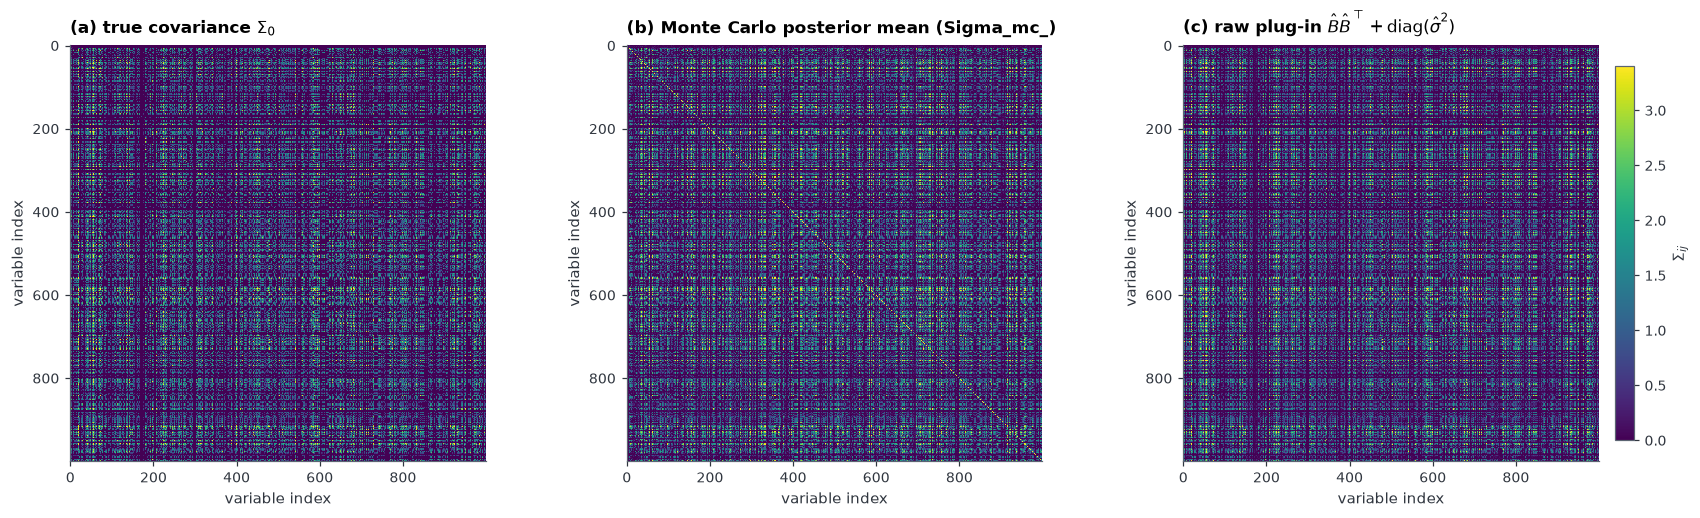

In [11]:
# Covariance heatmaps: truth, Monte Carlo mean, and raw plug-in on one
# shared color scale (all pre-RSP).
panels = (
    (r"(a) true covariance $\Sigma_0$", Sig_true),
    (r"(b) Monte Carlo posterior mean (Sigma_mc_)", Sig_mc),
    (r"(c) raw plug-in $\hat B\hat B^\top + \mathrm{diag}(\hat\sigma^2)$",
     Sig_plug_raw),
)
vmax = float(np.percentile(
    np.concatenate([np.asarray(M, dtype=float).ravel() for _, M in panels]),
    99.5,
))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
for ax, (title, M) in zip(axes, panels):
    im = ax.imshow(M, cmap="viridis", vmin=0.0, vmax=vmax,
                   interpolation="nearest")
    ax.set_title(title, loc="left")
    ax.set_xlabel("variable index")
    ax.set_ylabel("variable index")
    ax.grid(False)
cb = fig.colorbar(im, ax=axes, pad=0.01, shrink=0.9)
cb.set_label(r"$\Sigma_{ij}$")
plt.show()


## 6b. Posterior uncertainty of $\Sigma$

`Sigma_diag_var_` is the cheap entrywise variance of the diagonal (all draws, $O(SpH)$); `cov_Sigma(pairs)` gives arbitrary entry-pair covariances at $O(SH)$ per pair. The full `Sigma_var_` matrix costs $O(Sp^2H)$ and is budget-guarded (deterministic equidistant subsample + warning); use `posterior_sigma_var(max_draws=None)` to force it. These Monte Carlo moments use the raw draws and are invariant to the RSP alignment in Section 8, so this section is safe to rerun after alignment.


posterior SD of Sigma_jj: mean = 0.631 (all 1000 draws)
Var(Sigma_01) = 6.750e-02, Cov(Sigma_01, Sigma_23) = -2.034e-04


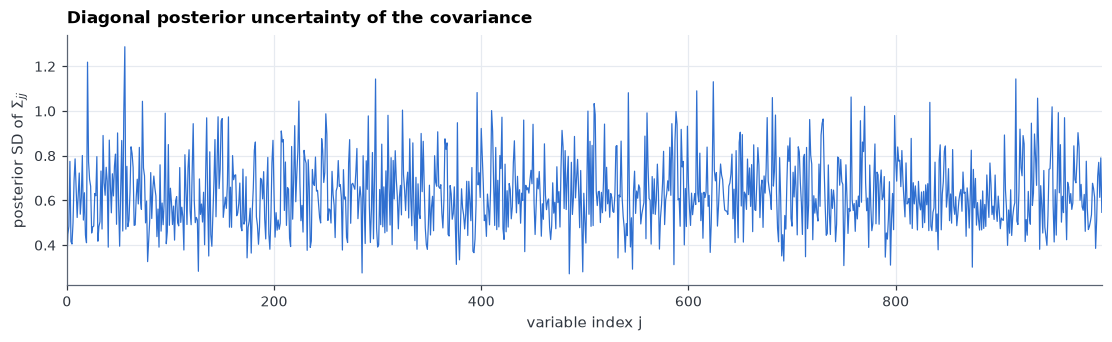

In [12]:
gs_sd_diag = np.sqrt(gs.Sigma_diag_var_)       # (p,), all draws, cheap
assert gs_sd_diag.shape == (P,) and np.all(gs_sd_diag >= 0)
pair_var = float(gs.cov_Sigma([((0, 1), (0, 1))])[0])
pair_cov = float(gs.cov_Sigma([((0, 1), (2, 3))])[0])
print(f"posterior SD of Sigma_jj: mean = {gs_sd_diag.mean():.3f} "
      f"(all {S} draws)")
print(f"Var(Sigma_01) = {pair_var:.3e}, "
      f"Cov(Sigma_01, Sigma_23) = {pair_cov:.3e}")

fig, ax = plt.subplots(figsize=(10, 3.0), constrained_layout=True)
ax.plot(gs_sd_diag, color=C_GS, lw=0.8)
ax.set_xlabel("variable index j")
ax.set_ylabel(r"posterior SD of $\Sigma_{jj}$")
ax.set_title("Diagonal posterior uncertainty of the covariance", loc="left")
ax.set_xlim(0, P - 1)
plt.show()


## 7. MCMC mixing diagnostics (ESS, ArviZ)

Single-chain bulk ESS of the raw loading and noise draws, plus the scalar $H^*$ chain. ArviZ is an optional dependency imported by `ess()`/`ess_summary()`. For a degenerate constant $H^*$ chain (e.g. the posterior concentrates on one dimension) the reported ESS equals the number of kept draws: there is no autocorrelation left to correct.


B        min=     1.5  median=   438.5  mean=   426.2  max=  1045.9  (draws=1000)
sigma2   min=   596.3  median=   929.0  mean=   925.4  max=  1216.0  (draws=1000)
H_star   min=  1000.0  median=  1000.0  mean=  1000.0  max=  1000.0  (draws=1000)
H* scalar chain ESS = 1000.0; a constant chain reports ESS = n_draws = 1000 by convention.


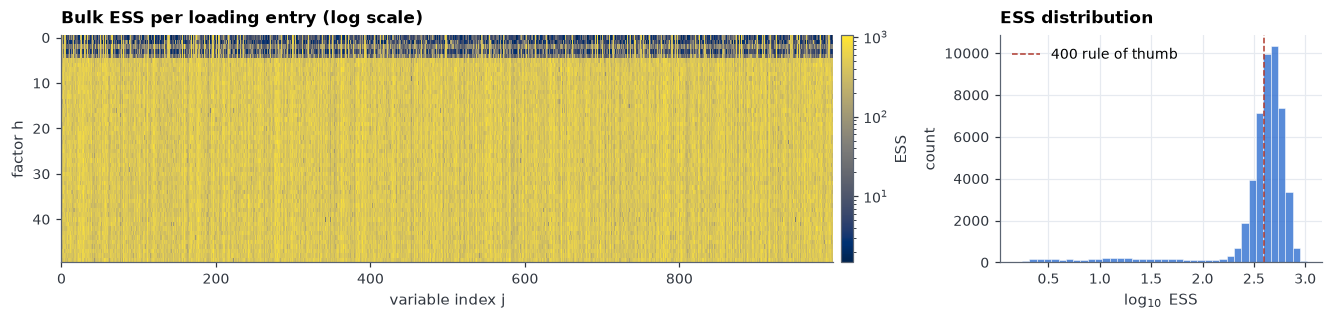

In [13]:
summary = gs.ess_summary()
for k, v in summary.items():
    print(f"{k:8s} min={v['min']:8.1f}  median={v['median']:8.1f}  "
          f"mean={v['mean']:8.1f}  max={v['max']:8.1f}  "
          f"(draws={v['n_draws']})")

hs_ess = summary["H_star"]
print(f"H* scalar chain ESS = {hs_ess['median']:.1f}; a constant chain "
      f"reports ESS = n_draws = {hs_ess['n_draws']} by convention.")

from matplotlib.colors import LogNorm

ess_B = gs.ess()["B"]
assert ess_B.shape == (P, H)
vals = ess_B.ravel()
vals = vals[np.isfinite(vals) & (vals > 0)]
assert vals.size > 0
ess_min, ess_max = float(np.min(vals)), float(np.max(vals))
ess_vmin = max(ess_min, 1e-6)
ess_vmax = max(ess_max, ess_vmin * 1.01)

fig, axes = plt.subplots(1, 2, figsize=(12, 2.8), constrained_layout=True,
                         gridspec_kw={"width_ratios": [2.4, 1.0]})
im = axes[0].imshow(ess_B.T, aspect="auto", interpolation="nearest",
                    norm=LogNorm(vmin=ess_vmin, vmax=ess_vmax),
                    cmap="cividis")
axes[0].set_title("Bulk ESS per loading entry (log scale)", loc="left")
axes[0].set_xlabel("variable index j")
axes[0].set_ylabel("factor h")
axes[0].grid(False)
cb = fig.colorbar(im, ax=axes[0], pad=0.01)
cb.set_label("ESS")
axes[1].hist(np.log10(vals), bins=40, color=C_GS, alpha=0.8,
             edgecolor="white", linewidth=0.4)
axes[1].axvline(np.log10(400.0), color=C_TRUE, ls="--", lw=1.0,
                label="400 rule of thumb")
axes[1].set_title("ESS distribution", loc="left")
axes[1].set_xlabel(r"$\log_{10}$ ESS")
axes[1].set_ylabel("count")
axes[1].legend(loc="upper left")
plt.show()


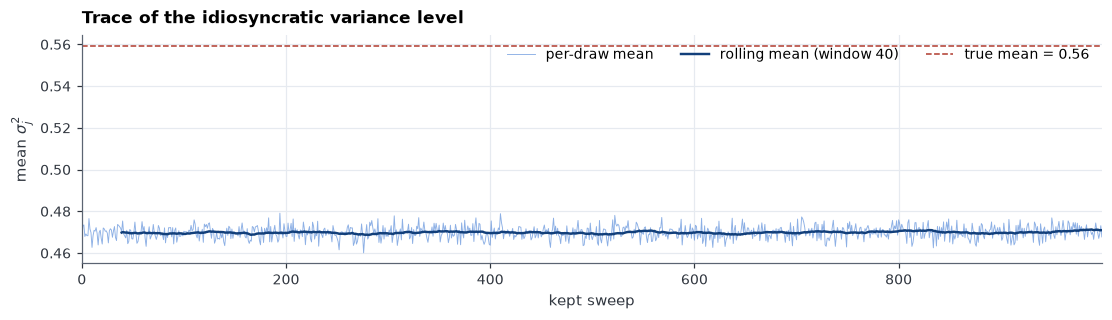

In [14]:
trace = gs.sigma2_samples_.mean(axis=1)
window = max(1, len(trace) // 25)
rolling = np.convolve(trace, np.ones(window) / window, mode="valid")

fig, ax = plt.subplots(figsize=(10, 2.8), constrained_layout=True)
ax.plot(trace, color=C_GS, lw=0.6, alpha=0.55, label="per-draw mean")
ax.plot(np.arange(window - 1, len(trace)), rolling, color="#123f7a",
        lw=1.6, label=f"rolling mean (window {window})")
ax.axhline(float(np.mean(s2_true)), color=C_TRUE, ls="--", lw=1.0,
           label=f"true mean = {float(np.mean(s2_true)):.2f}")
ax.set_xlabel("kept sweep")
ax.set_ylabel(r"mean $\sigma_j^2$")
ax.set_title("Trace of the idiosyncratic variance level", loc="left")
ax.set_xlim(0, len(trace) - 1)
ax.legend(loc="upper right", ncol=3)
plt.show()


## 8. Factor switching: RSP alignment and factor scores

All sections above used the raw draws. This is the **only** place where `gs.align_factors()` is called, and it runs after every pre-RSP analysis. For **H = 50**, RSP's default assignment backend requires Optax; from the `CSP_BFM` directory install `python -m pip install -e ".[rsp]"` if needed.

- `gs.align_factors()` aligns every retained draw (varimax + exact sign/permutation against a recursive reference) and updates `gs.B_hat_` to their aligned mean. `B_samples_` and ESS remain based on the original draws. Each draw's covariance $B B^\top$ is unchanged, but the plug-in `gs.Sigma_` can change because it uses the outer product of the new mean; `gs.Sigma_mc_` is invariant by construction.
- `gs.H_star_samples_` and `gs.n_factors()` (the $H^*$ rule) are computed in the prior's coordinate system and are unchanged: the increasing-shrinkage prior orders and spikes the columns, so the factor dimension is only meaningful before alignment. The marginal-credible-interval variant `n_factors(method="credible")` is invariant to sign flips and permutations but not to the varimax rotation; `use_aligned=True` switches its input draws.
- **Scores on demand:** `gs.sample_factors(X, ...)` draws scores conditional on each retained loading/noise pair. Pass the original uncentered `X`; the fitted centering offset is applied internally. These are fresh conditional draws, not the historical intermediate scores from the Gibbs sweeps.
- The snapshot below hashes the full raw `B_samples_` array without copying it and copies only the small summaries. Orientation alone does not establish better recovery: the column-dependent CSP prior is not invariant to general rotations or permutations — alignment selects a representation for display and comparison.


In [15]:
# Snapshot the raw state before the single alignment call.  B_samples_ is
# large (~S*p*H float32), so it is checked by a zero-copy digest rather than
# copied; the smaller summaries are copied so later assertions compare values.
def array_digest(a):
    a = np.asarray(a)
    if not a.flags.c_contiguous:
        raise ValueError("array_digest expects a C-contiguous array")
    return hashlib.blake2b(memoryview(a).cast("B"), digest_size=16).hexdigest()


B_samples_digest = array_digest(gs.B_samples_)
B_samples_shape = gs.B_samples_.shape
H_star_before = gs.H_star_samples_.copy()
sigma2_hat_before = gs.sigma2_hat_.copy()
Sigma_mc_before = gs.Sigma_mc_.copy()
n_factors_before = gs.n_factors()

# Raw loading mean and a small feature block for the score check in Section 8.
gs_mean_raw = gs.B_samples_.mean(axis=0)
check_features = np.unique(np.linspace(
    0, gs_mean_raw.shape[0] - 1, min(32, gs_mean_raw.shape[0]), dtype=int,
))
noise_block = np.diag(gs.sigma2_hat_[check_features])
gs_plugin_raw_block = (gs_mean_raw[check_features]
                       @ gs_mean_raw[check_features].T + noise_block)

gs.align_factors()
result = gs.rsp_result_
print(f"RSP: status={int(result.status_code)}, "
      f"stop={result.diagnostics['stop_reason']}, "
      f"iterations={int(result.n_iter)}, final loss={float(result.loss_final):.6g}")
print("diagnostics:", result.diagnostics)

assert array_digest(gs.B_samples_) == B_samples_digest
assert gs.B_samples_.shape == B_samples_shape
np.testing.assert_array_equal(gs.H_star_samples_, H_star_before)
np.testing.assert_array_equal(gs.sigma2_hat_, sigma2_hat_before)
np.testing.assert_array_equal(gs.Sigma_mc_, Sigma_mc_before)
assert gs.n_factors() == n_factors_before
assert gs.B_aligned_.shape == B_samples_shape
assert gs.rsp_result_.transforms.shape == (S, H, H)
np.testing.assert_allclose(gs.B_hat_, gs.B_aligned_.mean(axis=0),
                           rtol=2e-5, atol=2e-6)
print(f"raw B_samples_ digest {B_samples_digest[:12]}... unchanged; "
      "H*, sigma2_hat_, Sigma_mc_ and the default factor count are unchanged.")


RSP: status=1, stop=converged_threshold, iterations=33, final loss=2.13969e+06
diagnostics: {'initial_reference_near_zero': False, 'sp_path': 'elim', 'assignment_backend': 'auto', 'rotated': True, 'precision': 'float32', 'stop_reason': 'converged_threshold', 'nonfinite_fields': ()}


raw B_samples_ digest 73d88f3552aa... unchanged; H*, sigma2_hat_, Sigma_mc_ and the default factor count are unchanged.


### 8a. CSP audit: hyperparameters, counts, and all column norms

This is the CSP counterpart of the reference audit; it asserts the prior/truncation/seed and lists the dimension counts and every loading column's raw/aligned norms. `H*` is the raw-chain count in the prior's coordinate system: its default `n_factors()` value is alignment-invariant. The credible rule is reported on both the raw and the aligned draws because the varimax rotation can change it.

The norms below are **not** the Section 3 bars. Section 3 plots $\frac{1}{S}\sum_s \|B^{(s)}_{\cdot h}\|_2$, the mean of the per-draw $L_2$ column norms. Here, for each column $h$, we report:

- $\|\overline B_{\cdot h}\|_2$ for the raw posterior mean $\overline B=$ `B_samples_.mean(axis=0)` and for the aligned posterior mean `B_aligned_.mean(axis=0)`;
- $\max_j |\overline B_{jh}|$, the $L_\infty$ norm of the posterior-mean column.

The $L_\infty$ column is displayed for comparison only. No fixed absolute-threshold rule is applied to the CSP factor counts; all CSP counts come from $H^*$ or the credible-interval rule. Raw posterior-mean norms can be smaller than aligned ones because sign/permutation switching cancels columns in the raw mean; alignment removes that cancellation. This is not evidence of extra shrinkage at the spike.


In [16]:
expected_prior = {
    "H": H,
    "alpha": ALPHA,
    "a_theta": A_THETA,
    "b_theta": B_THETA,
    "theta_inf": THETA_INF,
    "a_sigma": A_SIGMA,
    "b_sigma": B_SIGMA,
}
for name, expected in expected_prior.items():
    actual = getattr(gs, name)
    assert actual == expected, (name, actual, expected)
    print(f"{name} = {actual:g}")
assert gs.seed_ == SAMPLER_SEED
assert (gs.n_iter, gs.burn_in, gs.thin) == (N_ITER, BURN_IN, THIN)
assert gs.B_samples_.shape == (S, P, H)
print(f"seed_ = {gs.seed_}; n_iter = {gs.n_iter}; burn_in = {gs.burn_in}; "
      f"thin = {gs.thin}")

h_summary = gs.h_star_summary()
r_h_star = gs.n_factors()
r_credible_raw = gs.n_factors(method="credible")
r_credible_aligned = gs.n_factors(method="credible", use_aligned=True)
assert 0 <= r_h_star <= H - 1
assert 0 <= r_credible_raw <= H
assert 0 <= r_credible_aligned <= H

print(f"\nH* posterior: mean={h_summary['mean']:.3f}, "
      f"median={h_summary['median']:.1f}, "
      f"95% CI=({h_summary['ci'][0]:.0f}, {h_summary['ci'][1]:.0f}), "
      f"draws={h_summary['n_draws']}; true r={K0}")
print(f"{'Factor-count method':<28}{'raw':>10}{'aligned':>10}")
print(f"{'H* median (int)':<28}{r_h_star:>10d}{'invariant':>10}")
print(f"{'credible 95% (HPD)':<28}{r_credible_raw:>10d}"
      f"{r_credible_aligned:>10d}")
print(f"H={H}; columns beyond the H* median = {H - r_h_star}; "
      f"at most H - 1 = {H - 1} can be active.")

B_raw_mean = gs.B_samples_.mean(axis=0)
B_aligned_mean = gs.B_aligned_.mean(axis=0)
raw_l2 = np.linalg.norm(B_raw_mean, axis=0)
aligned_l2 = np.linalg.norm(B_aligned_mean, axis=0)
raw_linf = np.max(np.abs(B_raw_mean), axis=0)
aligned_linf = np.max(np.abs(B_aligned_mean), axis=0)
for norms in (raw_l2, aligned_l2, raw_linf, aligned_linf):
    assert norms.shape == (H,)
    assert np.all(np.isfinite(norms))

print("\nPosterior-mean loading column norms (all columns):")
print(f"{'Column':>6}{'raw L2':>16}{'aligned L2':>16}"
      f"{'raw Linf':>16}{'aligned Linf':>16}")
for k in range(H):
    print(f"{k + 1:6d}{raw_l2[k]:16.9g}{aligned_l2[k]:16.9g}"
          f"{raw_linf[k]:16.9g}{aligned_linf[k]:16.9g}")
print("\nLinf entries are display-only; no threshold rule is applied to CSP counts.")


H = 50
alpha = 5
a_theta = 2
b_theta = 2
theta_inf = 0.05
a_sigma = 1
b_sigma = 0.3
seed_ = 2025; n_iter = 20000; burn_in = 10000; thin = 10



H* posterior: mean=5.000, median=5.0, 95% CI=(5, 5), draws=1000; true r=5
Factor-count method                raw   aligned
H* median (int)                      5 invariant
credible 95% (HPD)                   5         5
H=50; columns beyond the H* median = 45; at most H - 1 = 49 can be active.

Posterior-mean loading column norms (all columns):
Column          raw L2      aligned L2        raw Linf    aligned Linf
     1      28.0833721      23.0755844      2.66802502      2.03374648
     2      15.6076889      16.1263409      1.43565834      1.41589868
     3      15.3575468      17.7162056      1.27720821       1.5849576
     4      14.7049475      16.9196281       1.2720542      1.51747882
     5      14.1774054      17.9293461      1.29002225      1.57228076
     6     0.359868139      1.67199981    0.0393006541     0.560069382
     7     0.324456036      1.49824202    0.0316256583     0.277616888
     8     0.306291789      1.49899006    0.0370281301     0.234636575
     9     0

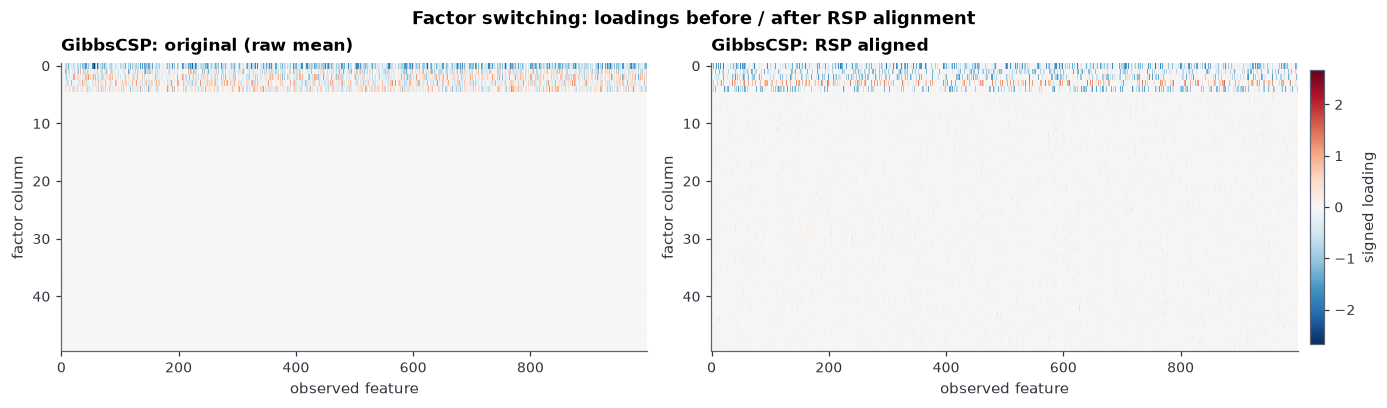

In [17]:
gs_mean_raw = gs.B_samples_.mean(axis=0)
assert gs_mean_raw.shape == (P, H)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), constrained_layout=True)
limit = max(float(np.max(np.abs(gs_mean_raw))),
            float(np.max(np.abs(gs.B_hat_))), 1e-8)
for ax, (label, loadings) in zip(axes, (("original (raw mean)", gs_mean_raw),
                                        ("RSP aligned", gs.B_hat_))):
    im = ax.imshow(loadings.T, aspect="auto", interpolation="nearest",
                   cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(f"GibbsCSP: {label}", loc="left")
    ax.set_xlabel("observed feature")
    ax.set_ylabel("factor column")
    ax.grid(False)
cb = fig.colorbar(im, ax=axes, pad=0.01, shrink=0.95)
cb.set_label("signed loading")
fig.suptitle("Factor switching: loadings before / after RSP alignment",
             fontweight="bold")
plt.show()


In [18]:
scores = gs.sample_factors(
    X, return_eta=True, return_eta_aligned=True, seed=SAMPLER_SEED, batch_size=32,
)
eta_sample = scores["eta_sample"]
eta_sample_aligned = scores["eta_sample_aligned"]
assert eta_sample.shape == (S, H, X.shape[0])
assert eta_sample_aligned.shape == (S, H, X.shape[0])
print("eta_sample / eta_sample_aligned:",
      eta_sample.shape, eta_sample_aligned.shape, "(S, H, n)")


def relative_difference(actual, expected):
    scale = max(float(np.linalg.norm(expected)), np.finfo(float).tiny)
    return float(np.linalg.norm(actual - expected)) / scale


# Compare paired scores for ONE draw and a small set of features.
s = S // 2
B_raw_selected = gs.B_samples_[s, check_features]
B_aligned_selected = gs.B_aligned_[s, check_features]
common_raw = B_raw_selected @ eta_sample[s]
common_aligned = B_aligned_selected @ eta_sample_aligned[s]
np.testing.assert_allclose(common_aligned, common_raw, rtol=1e-4, atol=1e-4)
cov_raw = B_raw_selected @ B_raw_selected.T
cov_aligned = B_aligned_selected @ B_aligned_selected.T
np.testing.assert_allclose(cov_aligned, cov_raw, rtol=1e-4, atol=1e-4)
print(f"draw {s}: relative B@eta difference = "
      f"{relative_difference(common_aligned, common_raw):.3e}; "
      f"relative BB.T submatrix difference = "
      f"{relative_difference(cov_aligned, cov_raw):.3e}")

gs_plugin_aligned_block = (gs.B_hat_[check_features]
                           @ gs.B_hat_[check_features].T + noise_block)
print("plug-in Sigma_ relative change on selected features:",
      f"{relative_difference(gs_plugin_aligned_block, gs_plugin_raw_block):.3e}")
# Sigma_ can change even though each aligned draw preserves BB.T.


eta_sample / eta_sample_aligned: (1000, 50, 100) (1000, 50, 100) (S, H, n)
draw 500: relative B@eta difference = 3.579e-07; relative BB.T submatrix difference = 2.975e-07
plug-in Sigma_ relative change on selected features: 5.224e-02


## Summary

- **Data**: sparse random loadings (about two-thirds exact zeros, nonzero entries $U(0.5, 1.5)$) and heteroscedastic noise at $n = 100 \ll p = 1000$, generated with `DATA_SEED = 2`.
- **Fit**: `GibbsCSP` with explicit CSP hyperparameters, `H = 50` (at most 49 columns active; the last is spiked by construction), 20,000 sweeps, 10,000 burn-in, thin 10, and `SAMPLER_SEED = 2025`.
- **Dimension**: compare the $H^*$ posterior (default median) and the secondary credible count with the true $r = 5$; columns beyond the reported dimension are designed to be absorbed by the increasing shrinkage. $H^*$ is defined in the prior's coordinate system and is not an aligned quantity.
- **Pre-RSP analyses**: noise recovery, absolute/relative covariance errors, principal-angle cosines, covariance heatmaps, and diagonal uncertainty all use raw draws. The plug-in covariance is built explicitly from `B_samples_.mean(axis=0)`, so rerunning Section 8 does not change these conclusions.
- **Mixing**: ESS is summarized per loading entry; the scalar $H^*$ chain follows the convention that a constant chain has ESS equal to the number of kept draws.
- **RSP**: one alignment call at the end. The raw `B_samples_` digest, $H^*$, `sigma2_hat_`, `Sigma_mc_`, and the default factor count are unchanged. Aligned posterior-mean column norms can be larger than raw ones because alignment removes sign/permutation cancellation, not because of extra shrinkage; the Section 8a table reports both representations.
- **Scores**: paired raw/aligned scores satisfy `B_aligned @ eta_aligned = B_raw @ eta_raw` up to the printed numerical difference, and the checked $BB^\top$ submatrix is preserved.
- Timing and RSP iteration counts are whatever this run prints; no historical values are assumed.
